# NYU Langone Patient Pathways
## 01 — Synthetic Data Exploration

### Objectives
- Explore the structure of synthetic Epic-like datasets.
- Assess missing values, duplicates, and data types.
- Validate relationships between patients, appointments, referrals, and hospital visits.
- Compare baseline and messy synthetic data.
- Identify issues for the data cleaning pipeline.

**Note:** All records are synthetic. Results do not represent actual NYU Langone patients.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Support running from project root or notebooks/
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

BASE_DIR = PROJECT_ROOT / "data" / "synthetic"

TABLE_NAMES = [
    "patients",
    "appointments",
    "referrals",
    "hospital_visits"
]

clean_data = {}
messy_data = {}

for name in TABLE_NAMES:
    clean_data[name] = pd.read_csv(
        BASE_DIR / "clean" / f"{name}.csv"
    )

    messy_data[name] = pd.read_csv(
        BASE_DIR / "messy" / f"{name}.csv"
    )

print("All datasets loaded successfully.")

Matplotlib is building the font cache; this may take a moment.


All datasets loaded successfully.


In [5]:
overview = []

for name in TABLE_NAMES:
    df = messy_data[name]

    overview.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "total_missing": df.isna().sum().sum(),
        "duplicate_rows": df.duplicated().sum()
    })

overview_df = pd.DataFrame(overview)

display(overview_df)

,dataset,rows,columns,total_missing,duplicate_rows
0,patients,5000,6,836,0
1,appointments,14142,8,8360,0
2,referrals,1978,7,900,0
3,hospital_visits,1000,4,0,0


In [6]:
for name in TABLE_NAMES:
    print(f"\n{name.upper()}")
    display(messy_data[name].head())


PATIENTS


,study_patient_id,age,sex,pcp_id,insurance_type,mychart_active
0,P00001,24.0,Female,PCP_A,Commercial,True
1,P00002,74.0,Female,PCP_C,Medicaid,True
2,P00003,65.0,Male,PCP_C,Commercial,True
3,P00004,50.0,Female,PCP_D,Medicaid,False
4,P00005,49.0,Female,PCP_C,Medicaid,True



APPOINTMENTS


,encounter_id,study_patient_id,booking_date,appointment_date,appointment_status,visit_type,visit_mode,return_interval_days
0,E000001,P00001,2025-08-19,2025-10-24,Completed,Annual Physical,Office,NaN
1,E000002,P00001,2024-04-04,2024-06-01,Completed,Follow-up,Video,365.0
2,E000003,P00001,2025-06-18,2025-09-30,Completed,Annual Physical,Office,365.0
3,E000004,P00002,2022-09-19,2022-10-09,Completed,New Patient,Office,365.0
4,E000005,P00002,2023-01-23,2023-02-02,Completed,Follow-up,Office,180.0



REFERRALS


,referral_id,study_patient_id,source_encounter_id,referral_date,specialty,referral_status,completion_date
0,R000001,P00049,E000134,2023-11-23,Dermatology,Completed,2024-01-01
1,R000002,P03767,E010656,2023-03-27,Dermatology,Closed without visit,NaN
2,R000003,P03237,E009161,2022-11-07,Dermatology,Closed without visit,NaN
3,R000004,P04593,E013000,2025-10-20,Orthopedics,Scheduled,NaN
4,R000005,P02817,E007918,2023-03-12,Endocrinology,Completed,2023-04-03



HOSPITAL_VISITS


,hospital_encounter_id,study_patient_id,admission_date,visit_category
0,H000001,P01195,2026-07-12,Urgent Care
1,H000002,P02189,2023-12-15,ED
2,H000003,P02576,2026-08-02,Urgent Care
3,H000004,P04283,2023-07-02,Urgent Care
4,H000005,P01919,2022-08-21,Urgent Care


In [7]:
missing_results = []

for name, df in messy_data.items():
    for column in df.columns:
        missing_results.append({
            "dataset": name,
            "column": column,
            "missing_count": df[column].isna().sum(),
            "missing_rate": (
                df[column].isna().mean() * 100
            )
        })

missing_df = pd.DataFrame(missing_results)

display(
    missing_df[
        missing_df["missing_count"] > 0
    ].sort_values(
        "missing_rate", ascending=False
    )
)

,dataset,column,missing_count,missing_rate
13,appointments,return_interval_days,8106,57.318625
20,referrals,completion_date,900,45.500506
4,patients,insurance_type,503,10.060000
5,patients,mychart_active,233,4.660000
1,patients,age,100,2.000000
10,appointments,appointment_status,254,1.796068


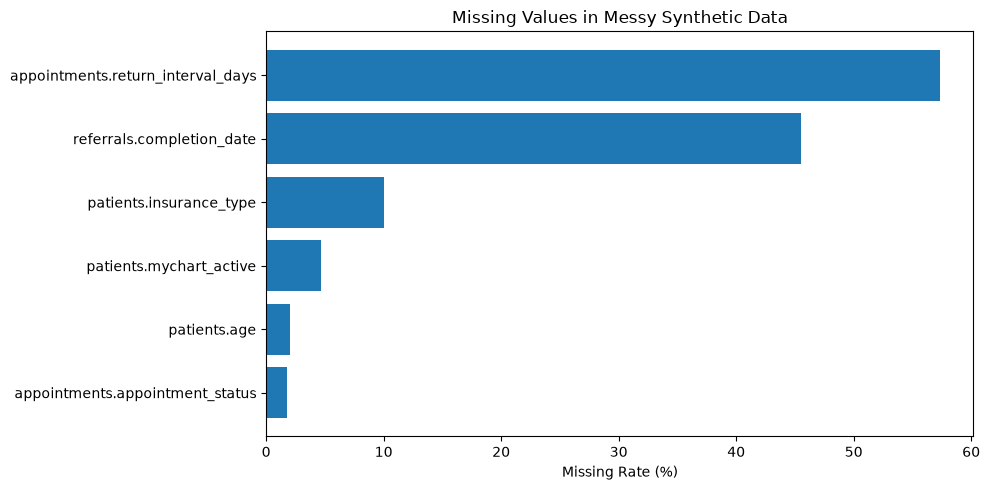

In [8]:
plot_df = missing_df[
    missing_df["missing_rate"] > 0
].sort_values("missing_rate")

plt.figure(figsize=(10, 5))

plt.barh(
    plot_df["dataset"] + "." + plot_df["column"],
    plot_df["missing_rate"]
)

plt.xlabel("Missing Rate (%)")
plt.title("Missing Values in Messy Synthetic Data")
plt.tight_layout()
plt.show()

In [9]:
PRIMARY_KEYS = {
    "patients": "study_patient_id",
    "appointments": "encounter_id",
    "referrals": "referral_id",
    "hospital_visits": "hospital_encounter_id"
}

key_results = []

for name, key in PRIMARY_KEYS.items():
    df = messy_data[name]

    key_results.append({
        "dataset": name,
        "primary_key": key,
        "missing_keys": df[key].isna().sum(),
        "duplicate_keys": df[key].duplicated().sum(),
        "unique_keys": df[key].nunique()
    })

display(pd.DataFrame(key_results))

,dataset,primary_key,missing_keys,duplicate_keys,unique_keys
0,patients,study_patient_id,0,0,5000
1,appointments,encounter_id,0,0,14142
2,referrals,referral_id,0,0,1978
3,hospital_visits,hospital_encounter_id,0,0,1000


In [10]:
patients = messy_data["patients"]
appointments = messy_data["appointments"]
referrals = messy_data["referrals"]
hospital = messy_data["hospital_visits"]

patient_ids = set(patients["study_patient_id"])

print(
    "Appointments with invalid patient IDs:",
    (~appointments["study_patient_id"].isin(patient_ids)).sum()
)

print(
    "Referrals with invalid patient IDs:",
    (~referrals["study_patient_id"].isin(patient_ids)).sum()
)

print(
    "Hospital visits with invalid patient IDs:",
    (~hospital["study_patient_id"].isin(patient_ids)).sum()
)

print(
    "Referrals with invalid source encounters:",
    (~referrals["source_encounter_id"].isin(
        appointments["encounter_id"]
    )).sum()
)

Appointments with invalid patient IDs: 0
Referrals with invalid patient IDs: 0
Hospital visits with invalid patient IDs: 0
Referrals with invalid source encounters: 0


In [11]:
for name, df in messy_data.items():
    print(f"\n{name.upper()}")
    print(df.dtypes)


PATIENTS
study_patient_id        str
age                 float64
sex                     str
pcp_id                  str
insurance_type          str
mychart_active       object
dtype: object

APPOINTMENTS
encounter_id                str
study_patient_id            str
booking_date                str
appointment_date            str
appointment_status          str
visit_type                  str
visit_mode                  str
return_interval_days    float64
dtype: object

REFERRALS
referral_id            str
study_patient_id       str
source_encounter_id    str
referral_date          str
specialty              str
referral_status        str
completion_date        str
dtype: object

HOSPITAL_VISITS
hospital_encounter_id    str
study_patient_id         str
admission_date           str
visit_category           str
dtype: object


In [12]:
appt_check = appointments.copy()
ref_check = referrals.copy()
hospital_check = hospital.copy()

appt_check["booking_date"] = pd.to_datetime(
    appt_check["booking_date"], errors="coerce"
)

appt_check["appointment_date"] = pd.to_datetime(
    appt_check["appointment_date"], errors="coerce"
)

ref_check["referral_date"] = pd.to_datetime(
    ref_check["referral_date"], errors="coerce"
)

ref_check["completion_date"] = pd.to_datetime(
    ref_check["completion_date"], errors="coerce"
)

hospital_check["admission_date"] = pd.to_datetime(
    hospital_check["admission_date"], errors="coerce"
)

In [13]:
invalid_booking_dates = (
    appt_check["booking_date"]
    > appt_check["appointment_date"]
).sum()

print("Invalid booking dates:", invalid_booking_dates)

invalid_referral_dates = (
    ref_check["completion_date"].notna()
    & (
        ref_check["completion_date"]
        < ref_check["referral_date"]
    )
).sum()

print("Invalid referral dates:", invalid_referral_dates)

Invalid booking dates: 0
Invalid referral dates: 0


In [14]:
display(
    appointments["appointment_status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="count")
)

,status,count
0,Completed,10800
1,Patient canceled,1387
2,No-show,1010
3,Clinic canceled,691
4,NaN,254


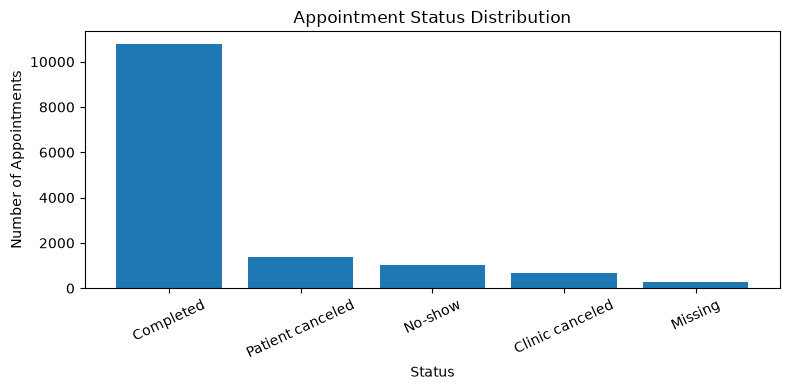

In [15]:
status_counts = (
    appointments["appointment_status"]
    .fillna("Missing")
    .value_counts()
)

plt.figure(figsize=(8, 4))
plt.bar(status_counts.index, status_counts.values)

plt.title("Appointment Status Distribution")
plt.xlabel("Status")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [16]:
display(
    referrals["referral_status"].value_counts(
        dropna=False
    )
)

referral_status
Completed               1078
Pending                  306
Scheduled                301
Closed without visit     201
Denied                    92
Name: count, dtype: int64

In [17]:
comparison_results = []

for name in TABLE_NAMES:
    clean = clean_data[name]
    messy = messy_data[name]

    for column in clean.columns:
        comparison_results.append({
            "dataset": name,
            "column": column,
            "clean_missing": clean[column].isna().sum(),
            "messy_missing": messy[column].isna().sum(),
            "additional_missing": (
                messy[column].isna().sum()
                - clean[column].isna().sum()
            )
        })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df[
        comparison_df["additional_missing"] != 0
    ]
)
for name in TABLE_NAMES:
    assert len(clean_data[name]) == len(messy_data[name])

print("All datasets have matching row counts.")

,dataset,column,clean_missing,messy_missing,additional_missing
1,patients,age,0,100,100
4,patients,insurance_type,0,503,503
5,patients,mychart_active,0,233,233
10,appointments,appointment_status,0,254,254


All datasets have matching row counts.


## Data Quality Summary

### 1. Dataset Structure
- Four synthetic datasets were generated.
- Patient, encounter, referral, and hospital encounter identifiers
  are used for record linkage.
- Primary key uniqueness and foreign key consistency were assessed.

### 2. Missing Values
- Additional missing values were introduced into age,
  insurance type, MyChart status, and appointment status.
- Missing return intervals and referral completion dates
  may reflect expected workflow conditions rather than errors.

### 3. Date Validation
- Booking and appointment dates were checked.
- Referral completion dates were checked against referral dates.

### 4. Issues for Data Cleaning
- Preserve unknown MyChart status rather than treating it as False.
- Do not automatically remove missing appointment statuses.
- Distinguish structural missingness from data quality problems.
- Standardize data types before calculating metrics.

### 5. Next Steps
- Develop reusable data cleaning functions.
- Define eligibility criteria for each research metric.
- Build and test analysis-ready datasets.